# Role A (OCR): first session

Needs the Colab secret `GITHUB_TOKEN` with **Notebook access** switched on for this notebook, and a GPU (Runtime > Change runtime type > GPU).

This notebook only checks that the data is ready and shows a few samples. Your own work goes into `src/ocr/` and into notebooks named `ocr_*`. Colab cannot push to GitHub: download your notebook (File > Download .ipynb), put it in the `notebooks/` folder of your clone and push from your laptop.

**First:** choose File > Save a copy in Drive and work in the copy, so the notebook in the shared folder stays clean for everybody. In the copy, switch on Notebook access for `GITHUB_TOKEN` again.


## 1. Connect to Drive and GitHub

In [21]:
from google.colab import drive, userdata

drive.mount("/content/drive")

BRANCH = "a/ocr"  # use your own branch (a/ocr, b/corrector, c/eval) to test code you have pushed

token = userdata.get("GITHUB_TOKEN").strip()
!rm -rf /content/repo
!git clone -q https://{token}@github.com/wickyhien18/Vietnamese-Handwriting-OCR.git /content/repo
!git -C /content/repo checkout -q {BRANCH}
%cd /content/repo
!pip install -q -r requirements.txt

import sys
sys.path.insert(0, "/content/repo")

DRIVE_ROOT = "/content/drive/MyDrive/Vietnamese-Handwriting-OCR"
DATA_DIR = f"{DRIVE_ROOT}/data"
CKPT_DIR = f"{DRIVE_ROOT}/checkpoints"
OUT_DIR = f"{DRIVE_ROOT}/outputs"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
fatal: Unable to read current working directory: No such file or directory
shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
fatal: cannot change to '/content/repo': No such file or directory
[Errno 2] No such file or directory: '/content/repo'
/content/repo
shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
The folder you are executing pip from can no longer be found.


## 2. Copy the images to the Colab disk and extract them

Reading thousands of small files from Drive is slow, so every session copies the zip to the Colab disk first.


In [22]:
import glob
import os
import shutil
import zipfile

UIT_DIR = f"{DATA_DIR}/uit_hwdb"
LOCAL_ROOT = "/content/uit_hwdb"
if not os.path.isdir(LOCAL_ROOT):
    archive_path = sorted(glob.glob(f"{UIT_DIR}/*.zip"))[0]
    shutil.copy(archive_path, "/content/uit_hwdb.zip")
    with zipfile.ZipFile("/content/uit_hwdb.zip") as archive:
        archive.extractall(LOCAL_ROOT)
print("images ready in", LOCAL_ROOT)


images ready in /content/uit_hwdb


In [23]:
import os, sys
from google.colab import userdata

# 1. Đưa thư mục làm việc về lại /content để hết lỗi getcwd
%cd /content

# 2. Tải lại repo từ GitHub
token = userdata.get("GITHUB_TOKEN").strip()
!rm -rf /content/repo
!git clone https://{token}@github.com/wickyhien18/Vietnamese-Handwriting-OCR.git /content/repo

# 3. Chuyển vào /content/repo, checkout nhánh và nạp sys.path
%cd /content/repo
!git checkout main
!pip install -q -r requirements.txt

if "/content/repo" not in sys.path:
    sys.path.insert(0, "/content/repo")

print("Thành công! Các file trong repo:", os.listdir("/content/repo"))

/content
Cloning into '/content/repo'...
remote: Enumerating objects: 143, done.
remote: Counting objects: 100% (143/143), done.
remote: Compressing objects: 100% (108/108), done.
remote: Total 143 (delta 48), reused 119 (delta 30), pack-reused 0 (from 0)
Receiving objects: 100% (143/143), 101.48 KiB | 7.25 MiB/s, done.
Resolving deltas: 100% (48/48), done.
/content/repo
Already on 'main'
Your branch is up to date with 'origin/main'.
Thành công! Các file trong repo: ['tests', 'notebooks', 'src', 'requirements.txt', 'docs', 'README.md', 'contracts', 'scripts', 'demo', '.git', '.gitignore']


## 3. Load the index and the splits

In [26]:
import sys, importlib
importlib.invalidate_caches()
if "/content/repo" not in sys.path:
    sys.path.insert(0, "/content/repo")

DRIVE_ROOT = "/content/drive/MyDrive/Vietnamese-Handwriting-OCR"
DATA_DIR = f"{DRIVE_ROOT}/data"
CKPT_DIR = f"{DRIVE_ROOT}/checkpoints"
OUT_DIR = f"{DRIVE_ROOT}/outputs"

from src.common.index_io import read_index, read_splits, select_split

index = read_index(f"{OUT_DIR}/dataset_index.jsonl")
splits = read_splits(f"{OUT_DIR}/splits.json")
for name in ("train", "val", "test"):
    print(name, len(select_split(index, splits, name)))

missing = [r["image_path"] for r in index[:50] if not os.path.exists(os.path.join(LOCAL_ROOT, r["image_path"]))]
print("missing among the first 50 images:", missing)
from src.common.index_io import read_index, read_splits, select_split

index = read_index(f"{OUT_DIR}/dataset_index.jsonl")
splits = read_splits(f"{OUT_DIR}/splits.json")
for name in ("train", "val", "test"):
    print(name, len(select_split(index, splits, name)))

missing = [r["image_path"] for r in index[:50] if not os.path.exists(os.path.join(LOCAL_ROOT, r["image_path"]))]
print("missing among the first 50 images:", missing)


train 6279
val 749
test 201
missing among the first 50 images: []
train 6279
val 749
test 201
missing among the first 50 images: []


## 4. Look at three samples (check that each image matches its text)

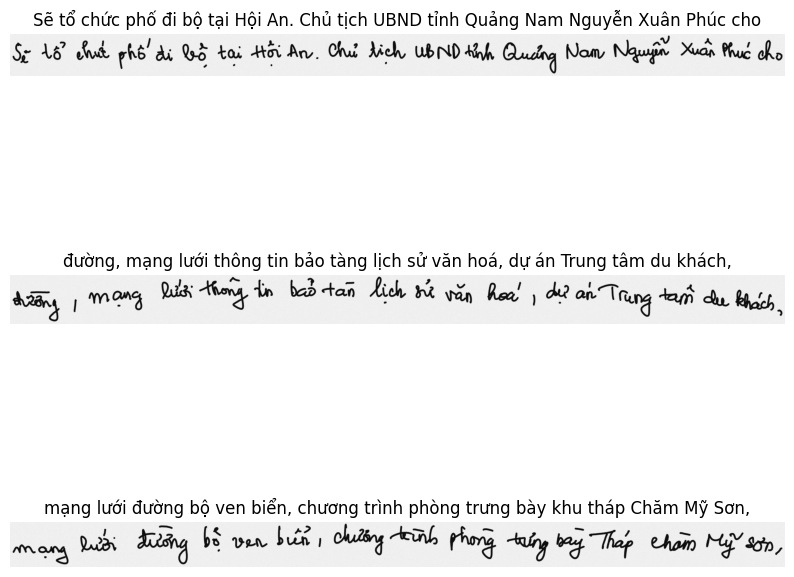

In [27]:
import matplotlib.pyplot as plt
from PIL import Image

samples = select_split(index, splits, "train")[:3]
fig, axes = plt.subplots(len(samples), 1, figsize=(10, 3 * len(samples)))
for ax, rec in zip(axes, samples):
    ax.imshow(Image.open(os.path.join(LOCAL_ROOT, rec["image_path"])), cmap="gray")
    ax.set_title(rec["gt_text"])
    ax.axis("off")
plt.show()


## 5. Check the GPU

In [28]:
import torch

print("CUDA available:", torch.cuda.is_available())


CUDA available: True


# 6. Vocab

In [29]:
import numpy as np
from PIL import Image
from collections import Counter

# Lấy 50 mẫu đầu tiên của tập train để test overfit
train_samples = select_split(index, splits, "train")
overfit_subset = train_samples[:50]

# Khảo sát kích thước 20 ảnh đầu tiên
heights, widths = [], []
for rec in train_samples[:20]:
    img = Image.open(os.path.join(LOCAL_ROOT, rec["image_path"]))
    w, h = img.size
    heights.append(h)
    widths.append(w)

print(f"Chiều cao trung bình: {np.mean(heights):.1f}, lớn nhất: {np.max(heights)}")
print(f"Chiều rộng trung bình: {np.mean(widths):.1f}, lớn nhất: {np.max(widths)}")
print("Quyết định: Chọn chiều cao cố định (fixed height) là 32 pixel.")

# Xây dựng bộ từ vựng từ toàn bộ tập train
vocab = set()
for rec in train_samples:
    vocab.update(list(rec["gt_text"]))
vocab = sorted(list(vocab))

# CTC yêu cầu 1 token đặc biệt là <blank> (thường để ở index 0)
char2idx = {char: idx + 1 for idx, char in enumerate(vocab)}
char2idx["<blank>"] = 0
idx2char = {idx: char for char, idx in char2idx.items()}
num_classes = len(char2idx)
print(f"Tổng số class (bao gồm blank): {num_classes}")

Chiều cao trung bình: 140.0, lớn nhất: 332
Chiều rộng trung bình: 2048.0, lớn nhất: 2048
Quyết định: Chọn chiều cao cố định (fixed height) là 32 pixel.
Tổng số class (bao gồm blank): 161


# 7. Tiền xử lý ảnh và PyTorch Dataset

In [30]:
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

class HWDBDataset(Dataset):
    def __init__(self, data_list, img_dir, char2idx, fixed_height=32):
        self.data_list = data_list
        self.img_dir = img_dir
        self.char2idx = char2idx
        self.fixed_height = fixed_height
        self.transform = T.Compose([
            T.ToTensor(),
            T.Normalize(mean=[0.5], std=[0.5]) # Chuẩn hóa ảnh[cite: 3]
        ])

    def __len__(self):
        return len(self.data_list)

    def __getitem__(self, idx):
        rec = self.data_list[idx]
        img_path = os.path.join(self.img_dir, rec["image_path"])
        # Chuyển sang ảnh xám[cite: 3]
        img = Image.open(img_path).convert("L")

        # Đổi kích thước với fixed_height[cite: 3]
        w, h = img.size
        new_w = int(w * (self.fixed_height / h))
        img = img.resize((new_w, self.fixed_height), Image.Resampling.BILINEAR)
        img_tensor = self.transform(img)

        # Chuyển text thành tensor nhãn
        text = rec["gt_text"]
        label = [self.char2idx[c] for c in text if c in self.char2idx]
        return img_tensor, torch.tensor(label, dtype=torch.long)

def collate_fn(batch):
    # Padding ảnh và nhãn để tạo batch
    images, labels = zip(*batch)

    # Pad chiều rộng ảnh
    max_w = max([img.shape[2] for img in images])
    padded_images = torch.zeros(len(images), 1, 32, max_w)
    for i, img in enumerate(images):
        padded_images[i, :, :, :img.shape[2]] = img

    # Tính độ dài của mỗi chuỗi nhãn (cần cho CTC loss)
    target_lengths = torch.tensor([len(l) for l in labels], dtype=torch.long)
    padded_labels = torch.nn.utils.rnn.pad_sequence(labels, batch_first=True, padding_value=0)

    return padded_images, padded_labels, target_lengths

# Tạo DataLoader cho 50 mẫu test
overfit_dataset = HWDBDataset(overfit_subset, LOCAL_ROOT, char2idx)
overfit_loader = DataLoader(overfit_dataset, batch_size=4, shuffle=True, collate_fn=collate_fn)

# 8. Kiến trúc CRNN Baseline

In [33]:
import torch.nn as nn
import torch.nn.functional as F

class CRNN(nn.Module):
    def __init__(self, num_classes, hidden_size=256):
        super(CRNN, self).__init__()
        # CNN Baseline (Giảm chiều cao từ 32 xuống 1 qua max pooling)
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=3, padding=1), nn.ReLU(True),
            nn.MaxPool2d(2, 2), # C: 64, H: 16, W: W/2
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(True),
            nn.MaxPool2d(2, 2), # C: 128, H: 8, W: W/4
            nn.Conv2d(128, 256, kernel_size=3, padding=1), nn.BatchNorm2d(256), nn.ReLU(True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1), nn.ReLU(True),
            nn.MaxPool2d((2, 2), (2, 1), (0, 1)), # C: 256, H: 4, W: W/4 + 1
            nn.Conv2d(256, 512, kernel_size=3, padding=1), nn.BatchNorm2d(512), nn.ReLU(True),
            nn.MaxPool2d((2, 2), (2, 1), (0, 1)), # C: 512, H: 2, W: W/4 + 2
            nn.Conv2d(512, 512, kernel_size=2, stride=1, padding=0), nn.BatchNorm2d(512), nn.ReLU(True)
            # C: 512, H: 1, W: W/4 + 1
        )
        # BiLSTM Baseline
        self.rnn = nn.LSTM(512, hidden_size, num_layers=2, bidirectional=True, batch_first=True)
        self.fc = nn.Linear(hidden_size * 2, num_classes)

    def forward(self, x):
        conv = self.cnn(x)
        # Bỏ qua chiều cao (H=1), đưa W lên làm chuỗi sequence cho LSTM
        b, c, h, w = conv.size()
        conv = conv.squeeze(2) # (b, c, w)
        conv = conv.permute(0, 2, 1) # (b, w, c)

        rnn_out, _ = self.rnn(conv)
        output = F.log_softmax(self.fc(rnn_out), dim=2)
        # CTC Loss trong PyTorch yêu cầu input shape: (Sequence Length, Batch Size, Num Classes)
        return output.permute(1, 0, 2)

# 9. Overfitting Loop

In [34]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CRNN(num_classes).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
# Sử dụng CTC Loss[cite: 3]
criterion = nn.CTCLoss(blank=0, zero_infinity=True)

# Đảm bảo thư mục lưu checkpoint tồn tại
ocr_ckpt_dir = f"{CKPT_DIR}/ocr"
os.makedirs(ocr_ckpt_dir, exist_ok=True)

print("Bắt đầu overfit 50 dòng...")
epochs = 50
for epoch in range(epochs):
    model.train()
    total_loss = 0

    for images, labels, target_lengths in overfit_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images) # Shape: (T, B, C)

        # Tính chiều dài thực tế của output CNN sequence
        input_lengths = torch.full(size=(images.size(0),), fill_value=outputs.size(0), dtype=torch.long)

        loss = criterion(outputs, labels, input_lengths, target_lengths)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(overfit_loader)
    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] - Loss: {avg_loss:.4f}")

    # Lưu checkpoint vào Drive sau mỗi epoch (tránh Colab ngắt kết nối)[cite: 3]
    torch.save(model.state_dict(), f"{ocr_ckpt_dir}/crnn_epoch_{epoch+1}.pth")

print("Hoàn tất overfit! Nếu loss giảm mạnh về gần 0, pipeline đã hoạt động đúng.")

Bắt đầu overfit 50 dòng...
Epoch [10/50] - Loss: 3.5794
Epoch [20/50] - Loss: 3.0143
Epoch [30/50] - Loss: 2.4307
Epoch [40/50] - Loss: 1.9591
Epoch [50/50] - Loss: 1.3332
Hoàn tất overfit! Nếu loss giảm mạnh về gần 0, pipeline đã hoạt động đúng.


#

# Phần 1: Tạo Dataloader full và train nháp


In [35]:
# ==========================================
# PHẦN 1: TẠO DATALOADER FULL & TRAIN NHÁP
# ==========================================

# 1. Lấy toàn bộ dữ liệu thật cho train và val
train_samples = select_split(index, splits, "train")
val_samples = select_split(index, splits, "val")

train_dataset = HWDBDataset(train_samples, LOCAL_ROOT, char2idx)
val_dataset = HWDBDataset(val_samples, LOCAL_ROOT, char2idx)

# Tăng batch_size lên 32 hoặc 64 (tùy VRAM GPU, 32 là mức an toàn)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

# 2. Khởi tạo lại model hoàn toàn mới (xóa bỏ bộ nhớ học vẹt 50 dòng lúc nãy)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CRNN(num_classes).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CTCLoss(blank=0, zero_infinity=True)

# 3. Train nhanh 3 epochs để có trọng số "chống cháy" kịp nộp 13/11[cite: 1, 3]
epochs = 3
print(f"Bắt đầu train trên toàn bộ {len(train_samples)} mẫu tập Train...")

for epoch in range(epochs):
    model.train()
    total_loss = 0
    for i, (images, labels, target_lengths) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)

        input_lengths = torch.full(size=(images.size(0),), fill_value=outputs.size(0), dtype=torch.long)

        loss = criterion(outputs, labels, input_lengths, target_lengths)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        # In log mỗi 50 batch để theo dõi tiến độ
        if (i + 1) % 50 == 0:
            print(f"Epoch [{epoch+1}/{epochs}], Step [{i+1}/{len(train_loader)}], Loss: {loss.item():.4f}")

    avg_loss = total_loss / len(train_loader)
    print(f"==> Hoàn thành Epoch {epoch+1} - Average Loss: {avg_loss:.4f}")

    # Lưu trọng số vào Drive sau MỖI epoch theo quy định của nhóm[cite: 3]
    torch.save(model.state_dict(), f"{CKPT_DIR}/ocr/crnn_full_epoch_{epoch+1}.pth")

print("Đã train xong bản nháp!")

Bắt đầu train trên toàn bộ 6279 mẫu tập Train...
Epoch [1/3], Step [50/197], Loss: 3.6433
Epoch [1/3], Step [100/197], Loss: 3.6563
Epoch [1/3], Step [150/197], Loss: 3.6033
==> Hoàn thành Epoch 1 - Average Loss: 3.8143
Epoch [2/3], Step [50/197], Loss: 3.6343
Epoch [2/3], Step [100/197], Loss: 3.5156
Epoch [2/3], Step [150/197], Loss: 3.5866
==> Hoàn thành Epoch 2 - Average Loss: 3.5071
Epoch [3/3], Step [50/197], Loss: 2.6877
Epoch [3/3], Step [100/197], Loss: 2.5452
Epoch [3/3], Step [150/197], Loss: 2.3360
==> Hoàn thành Epoch 3 - Average Loss: 2.5946
Đã train xong bản nháp!


# PHẦN 2: CTC GREEDY DECODING & XUẤT FILE

In [36]:
# ==========================================
# PHẦN 2: CTC GREEDY DECODING & XUẤT FILE
# ==========================================
import json
import numpy as np
from src.common.text_utils import normalize_nfc # Dùng để chuẩn hóa Unicode[cite: 1, 23]

# 1. Tự implement CTC Greedy Decoding bằng Numpy (phục vụ thi vấn đáp)[cite: 4]
def ctc_greedy_decode(probs, idx2char, blank=0):
    """
    probs: mảng numpy 2D có shape (Sequence Length, Num Classes)
    """
    # Lấy index có xác suất cao nhất tại mỗi frame
    preds = np.argmax(probs, axis=1)

    char_list = []
    prev_char = None

    for p in preds:
        # Bỏ qua token blank và các token trùng lặp liên tiếp
        if p != blank and p != prev_char:
            char_list.append(idx2char[p])
        prev_char = p

    return "".join(char_list)

# 2. Đưa model về chế độ suy luận và dự đoán trên tập validation
model.eval()
results = []
sample_idx = 0

print("Bắt đầu giải mã trên tập val...")
with torch.no_grad():
    # val_loader có shuffle=False, nên thứ tự ảnh khớp 100% với val_samples
    for images, labels, target_lengths in val_loader:
        images = images.to(device)

        # Lấy đầu ra của model
        outputs = model(images) # Shape: (SeqLen, Batch, Classes)
        outputs = outputs.permute(1, 0, 2) # Chuyển thành: (Batch, SeqLen, Classes)

        # Hàm CTCLoss dùng log_softmax, nên ta dùng torch.exp để đưa về xác suất (probs)
        probs_batch = torch.exp(outputs).cpu().numpy()

        for b in range(probs_batch.shape[0]):
            # Giải mã cho từng ảnh
            ocr_text = ctc_greedy_decode(probs_batch[b], idx2char, blank=0)

            # Lấy thông tin record tương ứng
            rec = val_samples[sample_idx]

            # Ghi nhận kết quả theo đúng cấu trúc hợp đồng[cite: 1, 22]
            results.append({
                "id": rec["id"],
                "split": "val", # Chỉ dùng tập val[cite: 1, 22]
                "image_path": rec["image_path"],
                "gt_text": rec["gt_text"], # Đã được chuẩn hóa NFC từ Bước 2
                "ocr_text": normalize_nfc(ocr_text) # Kể cả model đọc sai, vẫn phải chuẩn hóa NFC[cite: 1, 23]
            })
            sample_idx += 1

# 3. Ghi ra file ocr_out.jsonl trên Drive
out_path = f"{OUT_DIR}/ocr_out.jsonl"
with open(out_path, "w", encoding="utf-8") as f:
    for res in results:
        # Ghi từng dòng JSON, đảm bảo không lỗi font tiếng Việt[cite: 1]
        f.write(json.dumps(res, ensure_ascii=False) + "\n")

print(f"Đã xuất xong file kết quả tại: {out_path}")

Bắt đầu giải mã trên tập val...
Đã xuất xong file kết quả tại: /content/drive/MyDrive/Vietnamese-Handwriting-OCR/outputs/ocr_out.jsonl


In [37]:
!python scripts/validate_ocr_out.py {OUT_DIR}/ocr_out.jsonl

OK


## What to do next

1. Look at image sizes (height and width of 20 lines) and decide the fixed height for preprocessing.
2. Build the preprocessing and a small training loop, and make the model **overfit 50 training lines first**. If the loss does not go close to zero, the pipeline has a bug: find it before training on everything.
3. Save a checkpoint to `CKPT_DIR/ocr` after **every epoch** (Colab sessions get cut).
4. Measure validation CER with `corpus_error_rate` from `src/eval/align.py`.
5. Export `ocr_out.jsonl` (the contract fields, `image_path` as in the index) into `OUT_DIR` and check it with `python scripts/validate_ocr_out.py`.
